In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Literal

In [2]:
class NumberState(TypedDict):

    number: int
    result: str

In [3]:
def even_node(state: NumberState):

    return {'result': f"{state['number']} is even"}


def odd_node(state: NumberState):

    return {'result': f"{state['number']} is odd"}


# routing function: returns the name of the next node
def check_even_odd(state: NumberState) -> Literal['even_node', 'odd_node']:

    if state['number'] % 2 == 0:
        return 'even_node'
    else:
        return 'odd_node'

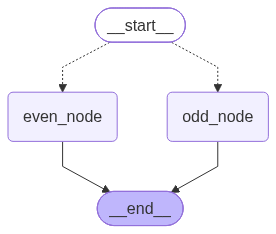

In [4]:
graph = StateGraph(NumberState)

graph.add_node('even_node', even_node)
graph.add_node('odd_node', odd_node)

# conditional edge: START -> check_even_odd decides which node runs
graph.add_conditional_edges(START, check_even_odd)

graph.add_edge('even_node', END)
graph.add_edge('odd_node', END)

workflow = graph.compile()
workflow

In [5]:
print(workflow.invoke({'number': 4}))
print(workflow.invoke({'number': 7}))

{'number': 4, 'result': '4 is even'}
{'number': 7, 'result': '7 is odd'}
